Implement calibrator for Tree.

Background: In the Black-Scholes model volatility is a key parameter that determines option price. In a Balanced Binomial Tree (i.e. risk-neutral up step probability = 0.5, risk-neutral down step probability=0.5) the same role is played by step size: higher step is like higher volatility, it results in higher option prices. Also, there is a 1-1 correspondence between step size and price if all other parameters are fixed.

Task: Write a calibrate method which, for a given number of steps parameter, computes the up step size for which a Balanced Binomial Tree model returns the specified price for a given European call. (In practice option prices can be observed in the market, so it makes sense to assume it is given). Demonstrate the calibrate method for various input parameters (same contract with a few different number of steps (dont forget to scale the discount factor to keep interest rates flat); calibrate one step tree for various contracts (different expiries and strike levels, flat interest rate)). Make simple plots to illustrate results.

Hint: To do it you will need to use a root solver, I recommend using scipy.optimize.minimize.

In [1]:
import numpy as np
from scipy.optimize import minimize
from collections.abc import Callable
import matplotlib.pyplot as plt

In [2]:
#recalling the code written in class
def european_call_payoff(S: float, K: float) -> float:
    return max(S - K, 0.0)

def create_spot_tree(spot: float, spot_mult_up: float, spot_mult_down: float, steps: int) -> list[list[float]]:
    previous_level = [spot]
    tree = [previous_level]
    for _ in range(steps):
        new_level = [s * spot_mult_down for s in previous_level]
        new_level += [previous_level[-1] * spot_mult_up]
        tree += [new_level]
        previous_level = new_level
    return tree

def create_discounted_price_tree(spot_tree: list[list[float]], discount_factor: float, K: float, diag: int = 0) -> list[list[float]]:
    spot = spot_tree[0][0]
    spot_mult_up = spot_tree[1][-1]
    spot_mult_down = spot_tree[1][0]
    p_up = ((1 / discount_factor - spot_mult_down) /
                   (spot_mult_up - spot_mult_down))
    p_down = 1 - p_up
    steps = len(spot_tree) - 1
    continuation_value_tree = [[np.nan for _ in level] for level in spot_tree]
    if diag > 0:
        print("risk-neutral measure: ")
        print(('%.3f' % p_up, '%.3f' % p_down))
        delta_tree = [[np.nan for _ in level] for level in spot_tree[:-1]]
    for i in range(len(spot_tree[-1])) :
        spot_val = spot_tree[-1][i]
        discounted_continuation_value = discount_factor**(steps) * european_call_payoff(spot_val, K)
        continuation_value_tree[-1][i] = discounted_continuation_value
    for step in range(steps - 1, -1, -1):
        for i in range(len(spot_tree[step])):
            continuation_value_tree[step][i] = p_up * continuation_value_tree[step + 1][i] + \
                                            p_down * continuation_value_tree[step + 1][i + 1]
            if diag > 0:
                delta_tree[step][i] = ((continuation_value_tree[step + 1][i] - continuation_value_tree[step + 1][i + 1]) 
                                       / (spot_tree[step + 1][i] - spot_tree[step + 1][i + 1]))
    if diag > 0:
        print("delta: ")
        delta_tree_readable = [['%.3f' % e for e in n] for n in delta_tree]
        print(delta_tree_readable)
    return continuation_value_tree

def calcBalancedDownStep(spot_mult_up: float, discount_factor: float) -> (float, float):
    return spot_mult_up - 2 * (spot_mult_up - 1 / discount_factor)

In [3]:
def calibrate_tree_up_step(target_price: float, spot: float, discount_factor: float, K: float, steps: int) -> float:
    def objective_function(u_val):
        u = u_val[0]
        
        #calculating the down step size 
        d = calcBalancedDownStep(u, discount_factor)
        
        #penalty condition 
        if d <= 0 or u <= 1 / discount_factor:
            return 1e6
            
        #creating the binomial spot price tree structure
        spot_tree = create_spot_tree(spot, u, d, steps)
        
        #calculating the discounted option price tree
        price_tree = create_discounted_price_tree(spot_tree, discount_factor, K, diag=0)
        
        #extracting the model price at the root of the tree 
        model_price = price_tree[0][0]

        #calculating the squared error
        err = (model_price - target_price)**2
        return err

    #an initial guess for the up-step size is needed for the 'minimize' function to run
    initial_guess = [1.1]
    
    #minimizing the objective function
    result = minimize(objective_function, initial_guess, method='Nelder-Mead')
    
    return result.x[0]

In [5]:
spot = 100.0
strike = 100.0
r_annual = 0.05
target_call_price = 8.5

In [7]:
#different number of steps
step_options = [1, 2, 5, 10, 20, 50]
calibrated_u_values = []

for n_steps in step_options:
    df_step = (1 / (1 + r_annual)) ** (1.0 / n_steps)
    u_opt = calibrate_tree_up_step(
        target_price=target_call_price, 
        spot=spot, 
        discount_factor=df_step, 
        K=strike, 
        steps=n_steps
    )
    calibrated_u_values.append(u_opt)
    print(f"steps: {n_steps:2d}, up-step: {u_opt:.4f}")

steps:  1, up-step: 1.2780
steps:  2, up-step: 1.6865
steps:  5, up-step: 1.2628
steps: 10, up-step: 1.3553
steps: 20, up-step: 1.6263
steps: 50, up-step: 1.4923


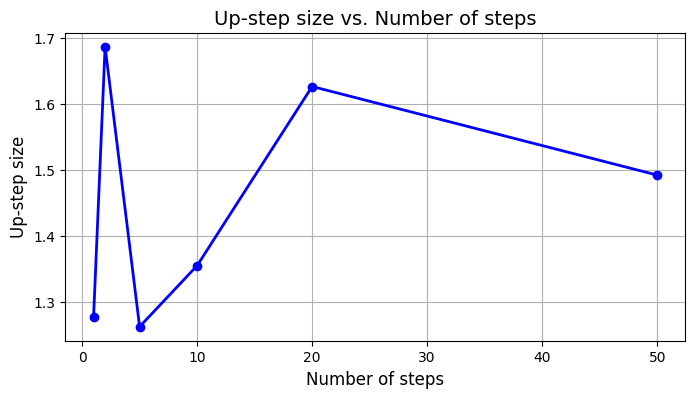

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(step_options, calibrated_u_values, marker='o', color='b', linewidth=2)
plt.title("Up-step size vs. Number of steps", fontsize=14)
plt.xlabel("Number of steps", fontsize=12)
plt.ylabel("Up-step size", fontsize=12)
plt.grid(True)
plt.show()

In [10]:
#different strike levels
strikes = [90.0, 95.0, 100.0, 105.0, 110.0]
target_prices_for_strikes = [14.0, 11.0, 8.5, 6.0, 4.0]
calibrated_u_strikes = []

df_one_step = 1 / (1 + r_annual)

for k_val, p_val in zip(strikes, target_prices_for_strikes):
    u_opt = calibrate_tree_up_step(
        target_price=p_val, 
        spot=spot, 
        discount_factor=df_one_step, 
        K=k_val, 
        steps=1
    )
    calibrated_u_strikes.append(u_opt)
    print(f"strike: {k_val:5.1f}, target price: {p_val:4.1f}, up-step: {u_opt:.4f}")

strike:  90.0, target price: 14.0, up-step: 1.1275
strike:  95.0, target price: 11.0, up-step: 1.3724
strike: 100.0, target price:  8.5, up-step: 1.2780
strike: 105.0, target price:  6.0, up-step: 1.0500
strike: 110.0, target price:  4.0, up-step: 1.1042


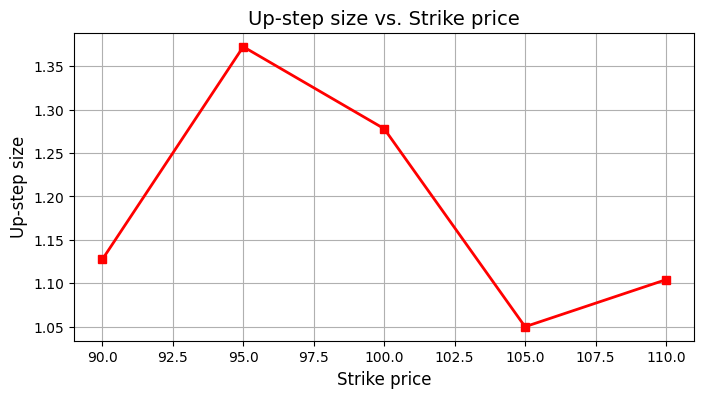

In [11]:

plt.figure(figsize=(8, 4))
plt.plot(strikes, calibrated_u_strikes, marker='s', color='r', linewidth=2)
plt.title("Up-step size vs. Strike price", fontsize=14)
plt.xlabel("Strike price", fontsize=12)
plt.ylabel("Up-step size", fontsize=12)
plt.grid(True)
plt.show()